In [1]:
from typing import Any
import pandas as pd
import numpy as np
from postgre_tools import Users, create_postgres_engine
import matplotlib.pyplot as plt


In [2]:
engine = create_postgres_engine(Users.AIRBNB.load_user())

# Set count to None if you want to fetch all rows
listings_row_count: int | None = None

if listings_row_count is not None and listings_row_count <= 0:
    raise ValueError("listings_row_count must be greater than 0")

listings_query = "SELECT id, price, room_type, accommodates, bedrooms, bathrooms, beds FROM listings"


if listings_row_count is not None:
    listings_query += f" LIMIT {listings_row_count}"


listings_df = pd.read_sql(listings_query, engine)

engine.dispose()

In [3]:
print(f"Columns in listings_df: {listings_df.columns}")
print(f"\nData types in listings_df:\n{listings_df.dtypes}")
listings_df

Columns in listings_df: Index(['id', 'price', 'room_type', 'accommodates', 'bedrooms', 'bathrooms',
       'beds'],
      dtype='str')

Data types in listings_df:
id                int64
price           float64
room_type           str
accommodates      int64
bedrooms        float64
bathrooms       float64
beds            float64
dtype: object


,id,price,room_type,accommodates,bedrooms,bathrooms,beds
0,145320,1503.50,Private room,2,1.0,1.0,1.0
1,164448,1030.00,Private room,2,NaN,1.0,2.0
2,220851,695.00,Private room,1,NaN,1.0,1.0
3,242188,972.00,Private room,1,NaN,1.0,1.0
4,273906,NaN,Entire home/apt,4,3.0,NaN,NaN
...,...,...,...,...,...,...,...
4801,1717861167246979973,NaN,Entire home/apt,2,1.0,1.0,1.0
4802,1718132464242032867,410.82,Private room,2,1.0,NaN,1.0
4803,1718263471917793029,456.47,Entire home/apt,2,1.0,0.5,1.0
4804,1718288866708700915,1266.50,Entire home/apt,2,1.0,NaN,1.0


In [4]:
features = ["room_type", "accommodates", "bedrooms", "bathrooms", "beds"]
clustering_features_df = listings_df[features]
clustering_features_df

,room_type,accommodates,bedrooms,bathrooms,beds
0,Private room,2,1.0,1.0,1.0
1,Private room,2,NaN,1.0,2.0
2,Private room,1,NaN,1.0,1.0
3,Private room,1,NaN,1.0,1.0
4,Entire home/apt,4,3.0,NaN,NaN
...,...,...,...,...,...
4801,Entire home/apt,2,1.0,1.0,1.0
4802,Private room,2,1.0,NaN,1.0
4803,Entire home/apt,2,1.0,0.5,1.0
4804,Entire home/apt,2,1.0,NaN,1.0


In [5]:
clustering_features_df.dtypes

room_type           str
accommodates      int64
bedrooms        float64
bathrooms       float64
beds            float64
dtype: object

In [6]:
# Check how many rows that does not have nan
clustering_features_df.dropna().shape[0]

2299

In [7]:
# Check how many values are missing for each column
clustering_features_df.isna().sum()

room_type          0
accommodates       0
bedrooms         697
bathrooms       2054
beds            1924
dtype: int64

In [8]:
# Check how many unique values there are in room_type column
unique_room_types = list(clustering_features_df["room_type"].unique())
unique_room_types

['Private room', 'Entire home/apt', 'Shared room', 'Hotel room']

In [9]:
# Count the number of listings for each room type
clustering_features_df["room_type"].value_counts()

room_type
Entire home/apt    3981
Private room        794
Shared room          28
Hotel room            3
Name: count, dtype: int64

In [10]:
numerical_features = ["accommodates", "bedrooms", "bathrooms", "beds"]

# Do a statistical summary of the numerical features
clustering_features_df[numerical_features].describe().T

,count,mean,std,min,25%,50%,75%,max
accommodates,4806.0,3.602788,2.089303,1.0,2.0,3.0,5.0,16.0
bedrooms,4109.0,1.920662,1.227736,0.0,1.0,1.0,3.0,12.0
bathrooms,2752.0,1.321766,0.762232,0.5,1.0,1.0,1.5,12.0
beds,2882.0,2.364330,1.834288,1.0,1.0,2.0,3.0,22.0


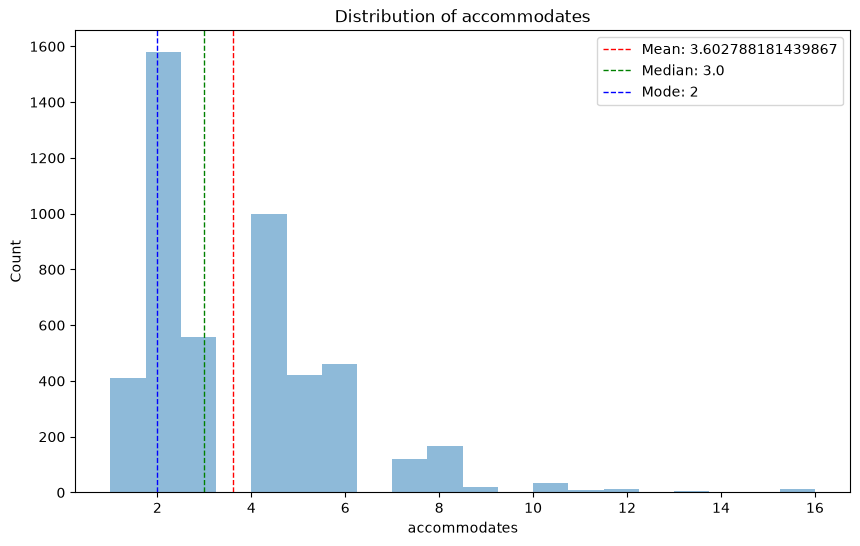

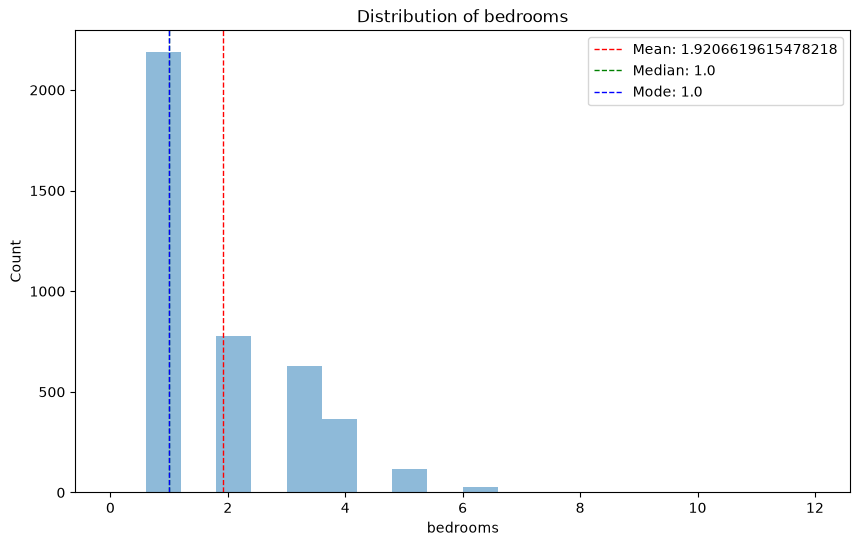

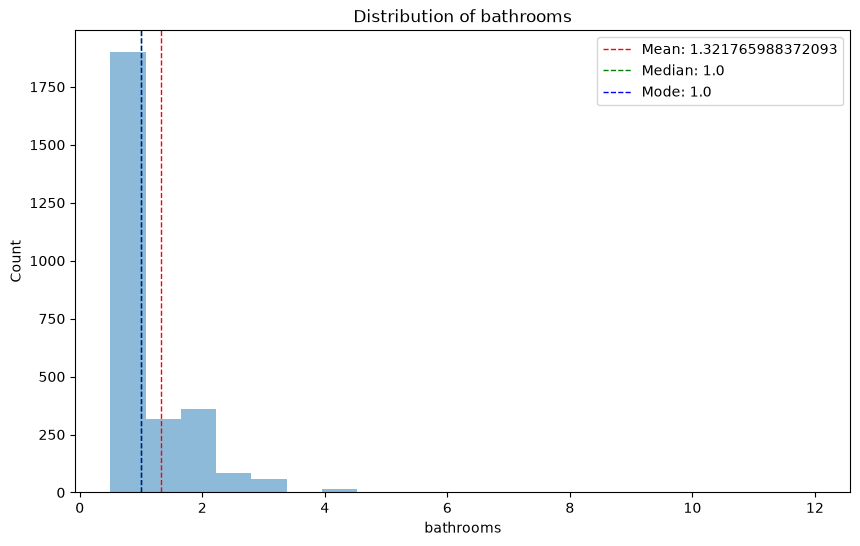

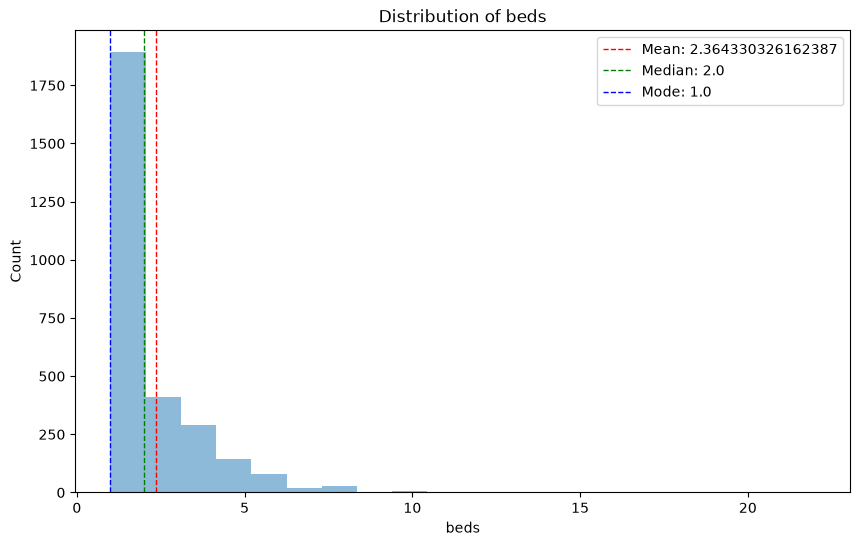

In [11]:
# print histograms for the numerical features. Include markers for mean, median, and mode
for feature in numerical_features:
    plt.figure(figsize=(10, 6))
    plt.hist(clustering_features_df[feature], bins=20, alpha=0.5)
    plt.xlabel(feature)
    plt.ylabel("Count")
    plt.title(f"Distribution of {feature}")
    mean_val = clustering_features_df[feature].mean()
    median_val = clustering_features_df[feature].median()
    mode_val = clustering_features_df[feature].mode()[0]
    plt.axvline(mean_val, color='r', linestyle='dashed', linewidth=1, label=f"Mean: {mean_val}")
    plt.axvline(median_val, color='g', linestyle='dashed', linewidth=1, label=f"Median: {median_val}")
    plt.axvline(mode_val, color='b', linestyle='dashed', linewidth=1, label=f"Mode: {mode_val}")
    plt.legend()
    plt.show()

ALl numerical features are mostly right skewed. If imputation global or grouped by imputation, then use median as it is more robust against outliers. 

# Imputation experiments

## Setup
Compare complete cases, global median, room-type median, and KNN imputation. All experiments use the previously defined `clustering_features_df` and `numerical_features`. The original data is never modified. KNN uses robust scaling (median/IQR) so that variables measured on different scales are comparable. The categorical `room_type` column is preserved, but is **not** used for KNN distances.

In [12]:
from sklearn.impute import KNNImputer
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import mean_absolute_error

missing_summary = pd.DataFrame({
    "missing_count": clustering_features_df.isna().sum(),
    "missing_percent": clustering_features_df.isna().mean().mul(100).round(2),
})
display(missing_summary)
print(f"Complete cases: {len(clustering_features_df.dropna()):,} / {len(clustering_features_df):,}")

,missing_count,missing_percent
room_type,0,0.00
accommodates,0,0.00
bedrooms,697,14.50
bathrooms,2054,42.74
beds,1924,40.03


Complete cases: 2,299 / 4,806


## Imputation methods
These functions fit their imputation statistics on the DataFrame supplied to them. They can therefore also be used with artificially masked data during evaluation. If a feature has no observed values anywhere, imputation fails explicitly instead of silently creating invalid clusters.

In [13]:
def _check_numeric_data(df: pd.DataFrame) -> None:
    empty_features = [col for col in numerical_features if df[col].notna().sum() == 0]
    if empty_features:
        raise ValueError(f"Cannot impute entirely missing numerical features: {empty_features}")


def impute_global_median(df: pd.DataFrame) -> pd.DataFrame:
    """Replace missing numeric values with each feature's global median."""
    _check_numeric_data(df)
    result = df.copy()
    result[numerical_features] = result[numerical_features].fillna(
        result[numerical_features].median()
    )
    return result


def impute_room_type_median(df: pd.DataFrame) -> pd.DataFrame:
    """Use medians within room_type, falling back to global medians."""
    _check_numeric_data(df)
    result = df.copy()
    group_medians = result.groupby("room_type")[numerical_features].transform("median")
    result[numerical_features] = (
        result[numerical_features]
        .fillna(group_medians)
        .fillna(result[numerical_features].median())
    )
    return result


def impute_knn(df: pd.DataFrame, n_neighbors: int = 5) -> pd.DataFrame:
    """KNN-impute numeric columns after robust scaling; preserve room_type."""
    _check_numeric_data(df)
    result = df.copy()
    numeric = result[numerical_features].astype(float)
    scaler = RobustScaler()
    scaled = scaler.fit_transform(numeric)
    imputed_scaled = KNNImputer(n_neighbors=n_neighbors).fit_transform(scaled)
    result[numerical_features] = scaler.inverse_transform(imputed_scaled)
    return result

## Baseline and complete imputed datasets
The complete-case baseline removes all rows with any missing feature. The imputed alternatives retain all rows. KNN can produce fractional bedroom/bed counts; these are left unrounded for evaluation. If integer counts are required in production, rounding is a separate modeling choice.

In [14]:
complete_cases_df = clustering_features_df.dropna().copy()

datasets = {
    "Complete cases": complete_cases_df,
    "Global median": impute_global_median(clustering_features_df),
    "Room-type median": impute_room_type_median(clustering_features_df),
    "KNN (k=5)": impute_knn(clustering_features_df, n_neighbors=5),
}

comparison = pd.DataFrame({
    "listings": {name: len(data) for name, data in datasets.items()},
    "missing_values_after": {name: int(data.isna().sum().sum()) for name, data in datasets.items()},
})
display(comparison)

# Example: datasets["Room-type median"]

,listings,missing_values_after
Complete cases,2299,0
Global median,4806,0
Room-type median,4806,0
KNN (k=5),4806,0


## Evaluate imputation with artificial missingness
For each repetition, randomly hide 20% of **observed** values in each numerical feature, impute from the remaining data, and compare against the original values using MAE. Values that were already missing are never treated as ground truth. Results are shown per feature, since bedroom counts and bathroom counts have different distributions. Note that simulated random missingness may not reproduce the real missingness mechanism.

In [15]:
def evaluate_imputation(
    df: pd.DataFrame,
    methods: dict,
    mask_fraction: float = 0.20,
    repeats: int = 5,
    seed: int = 42,
) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    records = []

    for repeat in range(repeats):
        masked_df = df.copy()
        masks = {}
        for feature in numerical_features:
            observed_indices = np.flatnonzero(df[feature].notna().to_numpy())
            n_mask = max(1, round(len(observed_indices) * mask_fraction))
            selected_positions = rng.choice(observed_indices, size=n_mask, replace=False)
            masks[feature] = selected_positions
            masked_df.iloc[selected_positions, masked_df.columns.get_loc(feature)] = np.nan

        for method_name, method in methods.items():
            imputed_df = method(masked_df)
            for feature in numerical_features:
                positions = masks[feature]
                truth = df[feature].iloc[positions].to_numpy(dtype=float)
                predicted = imputed_df[feature].iloc[positions].to_numpy(dtype=float)
                records.append({
                    "repeat": repeat + 1,
                    "method": method_name,
                    "feature": feature,
                    "mae": mean_absolute_error(truth, predicted),
                })

    return pd.DataFrame(records)


imputation_methods = {
    "Global median": impute_global_median,
    "Room-type median": impute_room_type_median,
    "KNN (k=5)": lambda df: impute_knn(df, n_neighbors=5),
}

imputation_errors = evaluate_imputation(
    clustering_features_df, imputation_methods, mask_fraction=0.20, repeats=5
)
mae_summary = imputation_errors.groupby(["method", "feature"])["mae"].agg(
    mean_mae="mean", std_mae="std"
).round(3)
display(mae_summary)

display(imputation_errors.pivot_table(
    index="method", columns="feature", values="mae", aggfunc="mean"
).round(3))

mean_mae  std_mae
method           feature                        
Global median    accommodates     1.605    0.023
                 bathrooms        0.339    0.052
                 bedrooms         0.935    0.032
                 beds             1.170    0.032
KNN (k=5)        accommodates     1.143    0.076
                 bathrooms        0.323    0.033
                 bedrooms         0.536    0.028
                 beds             0.823    0.044
Room-type median accommodates     1.397    0.041
                 bathrooms        0.339    0.052
                 bedrooms         0.935    0.032
                 beds             1.082    0.040

feature,accommodates,bathrooms,bedrooms,beds
method,,,,
Global median,1.605,0.339,0.935,1.170
KNN (k=5),1.143,0.323,0.536,0.823
Room-type median,1.397,0.339,0.935,1.082


# Clustering experiments: K-Means vs. K-Prototypes

Use **only** `datasets["KNN (k=5)"]` from the imputation experiments. The aim is to cluster properties based on `room_type`, `accommodates`, `bedrooms`, `bathrooms`, and `beds`—**not** price, location, or listing ID.

- **K-Means** requires a numeric matrix, so we robust-scale the numeric columns and one-hot encode `room_type`.
- **K-Prototypes** handles a mixed numeric/categorical matrix directly. We robust-scale numeric values and leave `room_type` categorical.
- Both algorithms use the **same listings** and candidate cluster counts. Their native objective/cost values are *not* comparable, so we evaluate both with a common silhouette representation and adjusted Rand index (ARI) stability across random seeds.

K-Prototypes is supplied by the `kmodes` package. Install it in your notebook environment if needed (`%pip install kmodes`).

In [ ]:
from time import perf_counter

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import OneHotEncoder, RobustScaler

try:
    from kmodes.kprototypes import KPrototypes
except ImportError as exc:
    raise ImportError(
        "K-Prototypes requires the 'kmodes' package. Run '%pip install kmodes' "
        "in a notebook cell, then rerun this section."
    ) from exc

# Configure how many clusters and random initializations to investigate.
CLUSTER_COUNTS = range(2, 9)
RANDOM_SEEDS = [42, 123, 2026]
SILHOUETTE_SAMPLE_SIZE = 1200  # Fixed subsample for faster and comparable evaluation

knn_clustering_df = datasets["KNN (k=5)"].copy()
cluster_features = ["room_type", *numerical_features]

if knn_clustering_df[cluster_features].isna().any().any():
    raise ValueError("The KNN-imputed clustering features still contain missing values.")
if knn_clustering_df["room_type"].isna().any():
    raise ValueError("room_type must be observed for K-Prototypes.")

# Only fit transformations on the selected dataset. Keep row order and index unchanged.
scaler = RobustScaler()
X_numeric = scaler.fit_transform(knn_clustering_df[numerical_features].astype(float))

onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
X_room_type = onehot.fit_transform(knn_clustering_df[["room_type"]])

# Same representation for both algorithms' silhouette evaluation (and K-Means fitting).
X_evaluation = np.column_stack([X_numeric, X_room_type])
X_kmeans = X_evaluation

# kmodes expects object dtype for the combined numeric and categorical matrix.
X_kprototypes = np.empty((len(knn_clustering_df), len(numerical_features) + 1), dtype=object)
X_kprototypes[:, :len(numerical_features)] = X_numeric
X_kprototypes[:, -1] = knn_clustering_df["room_type"].astype(str).to_numpy()
CATEGORICAL_INDICES = [len(numerical_features)]

print(f"Listings: {len(knn_clustering_df):,}")
print(f"Numerical features: {numerical_features}")
print(f"Categorical feature: room_type ({onehot.categories_[0].tolist()})")
print(f"K-Means input shape: {X_kmeans.shape}")
print(f"K-Prototypes input shape: {X_kprototypes.shape}")

Listings: 4,806
Numerical features: ['accommodates', 'bedrooms', 'bathrooms', 'beds']
Categorical feature: room_type (['Entire home/apt', 'Hotel room', 'Private room', 'Shared room'])
K-Means input shape: (4806, 8)
K-Prototypes input shape: (4806, 5)


## Fit models across different cluster counts

We compare `k = 2, ..., 8` using three random seeds. The **silhouette score** is computed in the *same* scaled-numeric + one-hot room-type space for both algorithms, making this a consistent external measure of separation. This representation is also the one K-Means optimizes; K-Prototypes optimizes a different mixed-type cost, so silhouette should not be the only criterion.

The **adjusted Rand index (ARI)** measures how consistently repeated fits assign pairs of listings to clusters (1 = identical partitions, close to 0 = chance-level agreement). `fit_seconds` records computation time. Report K-Means inertia and K-Prototypes cost separately; they are not directly comparable.

In [18]:
def fit_clustering_model(algorithm: str, k: int, seed: int):
    """Fit one clustering model and return (fitted model, labels, seconds)."""
    started = perf_counter()
    if algorithm == "K-Means":
        model = KMeans(n_clusters=k, n_init=10, random_state=seed)
        labels = model.fit_predict(X_kmeans)
    elif algorithm == "K-Prototypes":
        model = KPrototypes(
            n_clusters=k,
            init="Cao",
            n_init=2,
            max_iter=100,
            random_state=seed,
            verbose=0,
        )
        labels = model.fit_predict(X_kprototypes, categorical=CATEGORICAL_INDICES)
    else:
        raise ValueError(f"Unknown algorithm: {algorithm}")
    return model, np.asarray(labels, dtype=int), perf_counter() - started


def evaluate_clustering():
    """Evaluate fit quality and stability, retaining fits for later inspection."""
    evaluations = []
    fitted_models = {}
    for algorithm in ["K-Means", "K-Prototypes"]:
        for k in CLUSTER_COUNTS:
            runs = []
            for seed in RANDOM_SEEDS:
                model, labels, duration = fit_clustering_model(algorithm, k, seed)
                fitted_models[(algorithm, k, seed)] = (model, labels)
                # Use a fixed random_state so the same subsample is used across runs.
                if len(np.unique(labels)) > 1:
                    silhouette = silhouette_score(
                        X_evaluation,
                        labels,
                        sample_size=min(SILHOUETTE_SAMPLE_SIZE, len(labels)),
                        random_state=42,
                    )
                else:
                    silhouette = np.nan
                runs.append(labels)
                evaluations.append({
                    "algorithm": algorithm,
                    "k": k,
                    "seed": seed,
                    "silhouette": silhouette,
                    "fit_seconds": duration,
                    "smallest_cluster": int(np.bincount(labels, minlength=k).min()),
                    "native_cost": float(model.inertia_ if algorithm == "K-Means" else model.cost_),
                })
            # Each k has one pairwise ARI summary across the different seeds.
            pairwise_ari = [
                adjusted_rand_score(runs[i], runs[j])
                for i in range(len(runs)) for j in range(i + 1, len(runs))
            ]
            stability = float(np.mean(pairwise_ari)) if pairwise_ari else np.nan
            for record in evaluations[-len(RANDOM_SEEDS):]:
                record["mean_pairwise_ari"] = stability
    return pd.DataFrame(evaluations), fitted_models

clustering_runs, fitted_models = evaluate_clustering()
clustering_summary = (
    clustering_runs.groupby(["algorithm", "k"], as_index=False)
    .agg(
        mean_silhouette=("silhouette", "mean"),
        std_silhouette=("silhouette", "std"),
        mean_pairwise_ari=("mean_pairwise_ari", "mean"),
        mean_fit_seconds=("fit_seconds", "mean"),
        min_cluster_size=("smallest_cluster", "min"),
        mean_native_cost=("native_cost", "mean"),
    )
)
display(clustering_summary.round(3))

,algorithm,k,mean_silhouette,std_silhouette,mean_pairwise_ari,mean_fit_seconds,min_cluster_size,mean_native_cost
0,K-Means,2,0.614,0.000,1.000,0.098,955,13404.242
1,K-Means,3,0.610,0.000,1.000,0.026,9,9331.652
2,K-Means,4,0.443,0.000,1.000,0.030,9,7146.080
3,K-Means,5,0.488,0.000,1.000,0.033,9,5997.036
4,K-Means,6,0.494,0.000,1.000,0.040,9,5086.585
5,K-Means,7,0.494,0.000,1.000,0.074,4,4508.857
6,K-Means,8,0.498,0.003,0.977,0.060,4,3968.196
7,K-Prototypes,2,0.613,0.000,1.000,1.104,957,12507.733
8,K-Prototypes,3,0.523,0.089,0.576,2.100,9,9647.450
9,K-Prototypes,4,0.418,0.035,0.644,1.500,9,8680.480


## Compare silhouette, stability, and computational time

Higher silhouette and ARI are generally preferable, but choose `k` based on whether the **cluster profiles are meaningful and sufficiently populated**, not just the maximum score. The native cost chart is split by algorithm because inertia and K-Prototypes cost use different units.

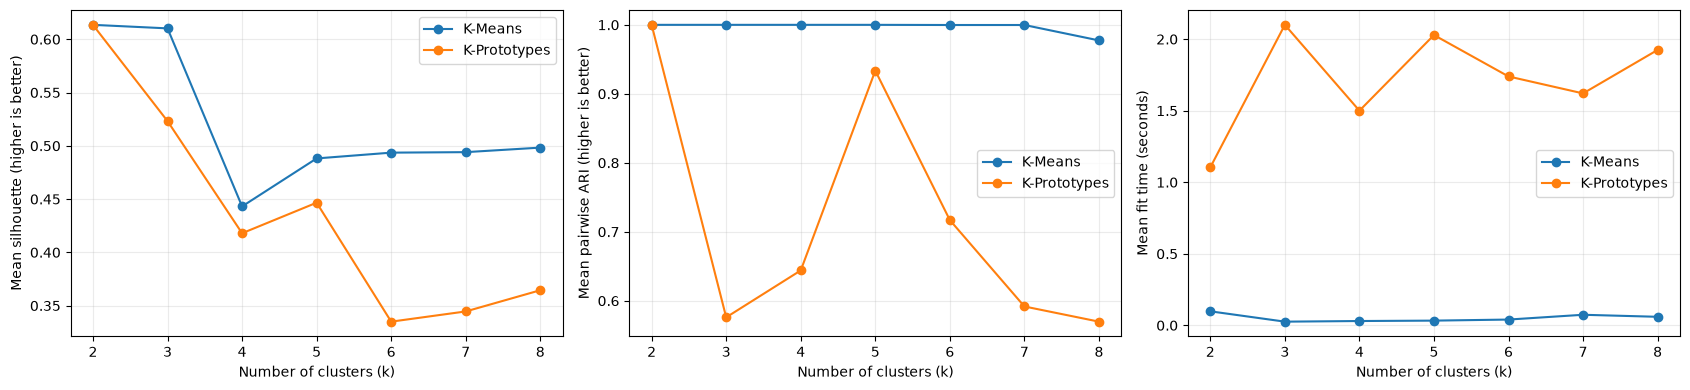

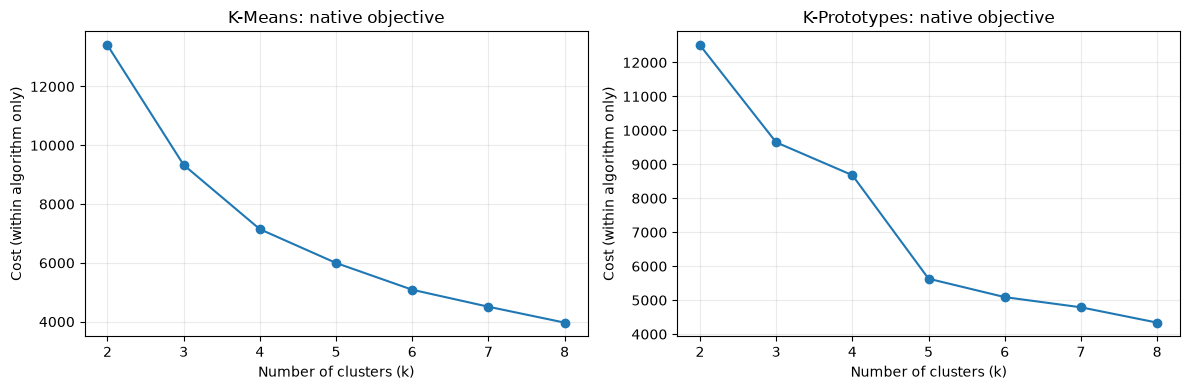

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
metrics = [
    ("mean_silhouette", "Mean silhouette (higher is better)"),
    ("mean_pairwise_ari", "Mean pairwise ARI (higher is better)"),
    ("mean_fit_seconds", "Mean fit time (seconds)"),
]
for ax, (metric, label) in zip(axes, metrics):
    for algorithm, group in clustering_summary.groupby("algorithm"):
        ax.plot(group["k"], group[metric], marker="o", label=algorithm)
    ax.set_xlabel("Number of clusters (k)")
    ax.set_ylabel(label)
    ax.set_xticks(list(CLUSTER_COUNTS))
    ax.grid(alpha=0.25)
    ax.legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, algorithm in zip(axes, ["K-Means", "K-Prototypes"]):
    group = clustering_summary.query("algorithm == @algorithm")
    ax.plot(group["k"], group["mean_native_cost"], marker="o")
    ax.set(title=f"{algorithm}: native objective", xlabel="Number of clusters (k)", ylabel="Cost (within algorithm only)")
    ax.set_xticks(list(CLUSTER_COUNTS))
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Inspect clusters and nightly-price distributions

The next cells select the `k` with the highest mean silhouette **within each algorithm** as an initial candidate. You can override either value after inspecting the plots. For each model we display cluster sizes, median accommodation characteristics, room-type composition, and nightly-price distributions. **Price is only used after fitting for interpretation, never as a clustering feature.**

Cluster numbers are arbitrary and cannot be compared directly between algorithms; use their profiles instead.

In [ ]:
suggested_k = (
    clustering_summary.sort_values(["algorithm", "mean_silhouette"], ascending=[True, False])
    .drop_duplicates("algorithm")
    .set_index("algorithm")["k"]
    .astype(int)
    .to_dict()
)
print("Suggested k by mean silhouette:", suggested_k)
# suggested_k = {'K-Means': 7, 'K-Prototypes': 7}

# Manually adjust these values based on interpretability and cluster stability.
SELECTED_K = {
    "K-Means": suggested_k["K-Means"],
    "K-Prototypes": suggested_k["K-Prototypes"],
}
SELECTED_SEED = RANDOM_SEEDS[0]

cluster_assignments = {}
for algorithm, k in SELECTED_K.items():
    model, labels = fitted_models[(algorithm, k, SELECTED_SEED)]
    assignments = knn_clustering_df.copy()
    assignments["cluster"] = labels
    # Only attach metadata for descriptive analysis; never feed it to clustering.
    if "price" in listings_df.columns:
        assignments["price"] = listings_df.loc[assignments.index, "price"]
    if "id" in listings_df.columns:
        assignments["listing_id"] = listings_df.loc[assignments.index, "id"]
    cluster_assignments[algorithm] = assignments


def show_cluster_profiles(algorithm: str) -> None:
    assigned = cluster_assignments[algorithm]
    print(f"\n{algorithm} — k={SELECTED_K[algorithm]}")
    numeric_summary = assigned.groupby("cluster").agg(
        listings=("room_type", "size"),
        **{f"median_{feature}": (feature, "median") for feature in numerical_features},
    )
    numeric_summary["percent_of_listings"] = (
        numeric_summary["listings"] / len(assigned) * 100
    ).round(1)
    display(numeric_summary.round(2))
    composition = pd.crosstab(assigned["cluster"], assigned["room_type"], normalize="index") * 100
    print("Room-type composition (% within cluster):")
    display(composition.round(1))
    if "price" in assigned.columns:
        print("Nightly-price distribution (descriptive only):")
        price = pd.to_numeric(assigned["price"], errors="coerce")
        price_profile = (
            assigned.assign(price_numeric=price)
            .groupby("cluster")["price_numeric"]
            .agg(count="count", median="median", mean="mean", std="std", min="min", max="max")
        )
        display(price_profile.round(2))

for algorithm in SELECTED_K:
    show_cluster_profiles(algorithm)

Suggested k by mean silhouette: {'K-Means': 2, 'K-Prototypes': 2}

K-Means — k=7


,listings,median_accommodates,median_bedrooms,median_bathrooms,median_beds,percent_of_listings
cluster,,,,,,
0,2112,2.0,1.0,1.0,1.2,43.9
1,262,8.0,4.0,2.5,5.0,5.5
2,4,16.0,12.0,12.0,22.0,0.1
3,998,4.0,2.0,1.0,3.0,20.8
4,5,6.0,1.0,9.0,6.0,0.1
5,662,6.0,3.0,2.0,4.0,13.8
6,763,2.0,1.0,1.0,1.0,15.9


Room-type composition (% within cluster):


room_type,Entire home/apt,Hotel room,Private room,Shared room
cluster,,,,
0,99.9,0.0,0.0,0.1
1,93.9,0.0,5.0,1.1
2,75.0,0.0,25.0,0.0
3,98.2,0.0,1.5,0.3
4,0.0,0.0,20.0,80.0
5,97.1,0.0,2.6,0.3
6,0.0,0.4,97.9,1.7


Nightly-price distribution (descriptive only):


,count,median,mean,std,min,max
cluster,,,,,,
0,1380,1653.30,1834.18,1063.89,32.47,13951.00
1,202,4029.34,4526.10,2996.23,262.00,30000.00
2,4,24495.00,24495.75,1732.92,22995.00,25998.00
3,608,2758.94,3023.15,2199.26,130.29,40000.00
4,5,325.00,398.00,173.30,270.00,700.00
5,494,3421.27,3757.06,2056.98,315.00,25714.29
6,571,810.24,972.70,809.52,36.23,9424.00


... (2 outputs left out)

Room-type composition (% within cluster):


room_type,Entire home/apt,Hotel room,Private room,Shared room
cluster,,,,
0,92.1,0.0,7.5,0.5
1,94.2,0.0,4.6,1.2
2,18.9,0.0,81.1,0.0
3,72.3,0.1,27.0,0.5
4,96.8,0.0,2.8,0.4
5,95.6,0.0,4.1,0.3
6,33.3,0.0,22.2,44.4


Nightly-price distribution (descriptive only):


,count,median,mean,std,min,max
cluster,,,,,,
0,718,2163.50,2373.70,1248.76,166.57,8159.50
1,199,4034.17,4556.23,3002.70,262.00,30000.00
2,47,730.50,1043.57,769.95,273.88,3243.00
3,1511,1276.85,1489.83,1068.26,32.47,13951.00
4,362,3104.46,3431.74,2623.99,130.29,40000.00
5,418,3363.65,3687.66,2158.57,125.97,25714.29
6,9,700.00,11108.11,12745.47,270.00,25998.00


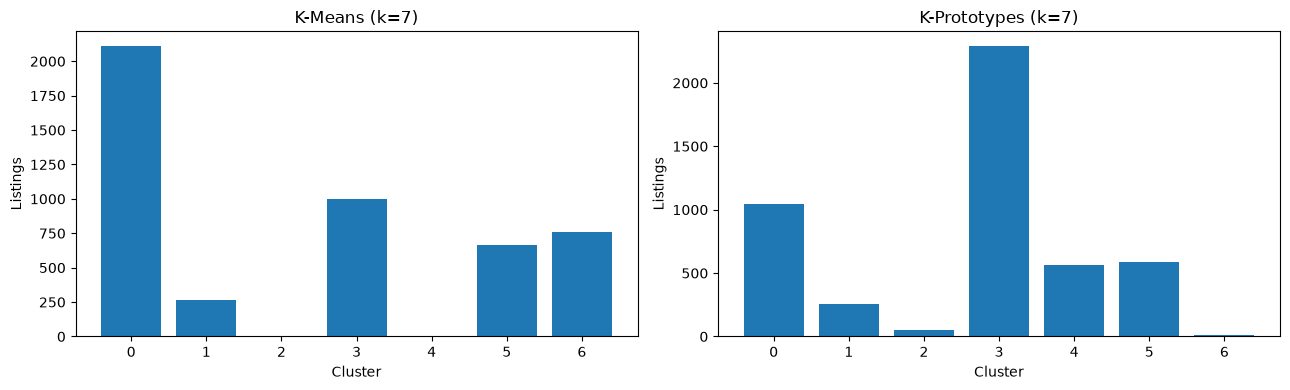

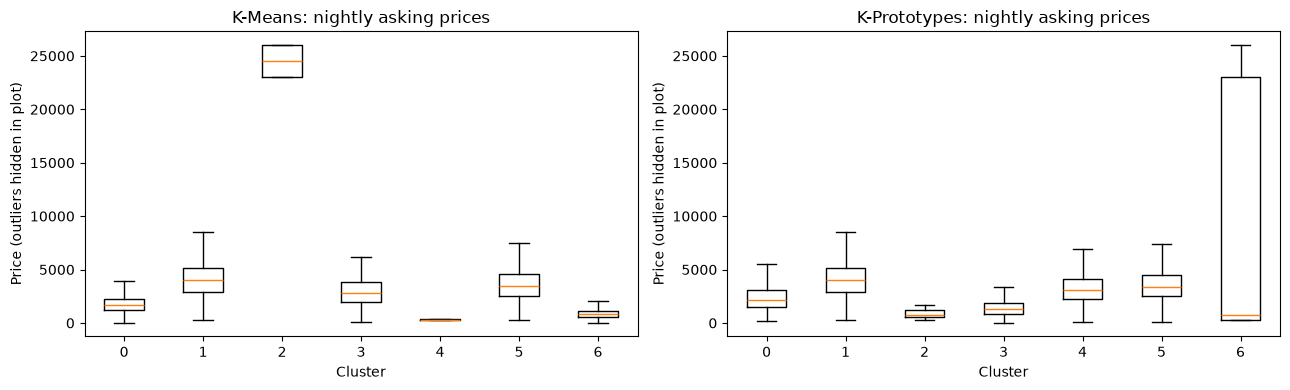

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, algorithm in zip(axes, ["K-Means", "K-Prototypes"]):
    assigned = cluster_assignments[algorithm]
    sizes = assigned["cluster"].value_counts().sort_index()
    ax.bar(sizes.index.astype(str), sizes.to_numpy())
    ax.set(title=f"{algorithm} (k={SELECTED_K[algorithm]})", xlabel="Cluster", ylabel="Listings")
plt.tight_layout()
plt.show()

if "price" in listings_df.columns:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for ax, algorithm in zip(axes, ["K-Means", "K-Prototypes"]):
        assigned = cluster_assignments[algorithm].copy()
        assigned["price"] = pd.to_numeric(assigned["price"], errors="coerce")
        price_groups = [
            assigned.loc[assigned["cluster"] == cluster, "price"].dropna().to_numpy()
            for cluster in sorted(assigned["cluster"].unique())
        ]
        if any(len(group) for group in price_groups):
            ax.boxplot(price_groups, tick_labels=[str(x) for x in sorted(assigned["cluster"].unique())], showfliers=False)
        ax.set(title=f"{algorithm}: nightly asking prices", xlabel="Cluster", ylabel="Price (outliers hidden in plot)")
    plt.tight_layout()
    plt.show()